# Implementing GPT2 Model

## 1. Install and Import Package

In [24]:
from importlib.metadata import version

print("matplotlib version:", version("matplotlib"))
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

matplotlib version: 3.10.0
torch version: 2.5.1
tiktoken version: 0.9.0


## 2. Global Configuration

In [25]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/03.webp" width="600px">

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/04.webp?123" width="600px">

## 3. Tokenizer

In [26]:
import tiktoken
import torch 
import torch.nn as nn 

tokenizer = tiktoken.get_encoding("gpt2")

real_batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

real_batch.append(torch.tensor(tokenizer.encode(txt1)))
real_batch.append(torch.tensor(tokenizer.encode(txt2)))

real_batch = torch.stack(real_batch, dim=0)
print(real_batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


## 4. LLM Architecture

### 4.1 Layer Normalization

- Layer normalization, also known as LayerNorm ([Ba et al. 2016](https://arxiv.org/abs/1607.06450)), centers the activations of a neural network layer around a mean of 0 and normalizes their variance to 1
- This stabilizes training and enables faster convergence to effective weights
- Layer normalization is applied both before and after the multi-head attention module within the transformer block, which we will implement later; it's also applied before the final output layer

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/05.webp" width="600px">

### 4.1.1 Motivation

Each input is centered at 0 and has a unit variance of 1; to improve readability, we can disable PyTorch's scientific notation:

In [27]:
torch.manual_seed(2024)

batch_exmaple = torch.randn(2, 5)

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
output = layer(batch_exmaple)
print(f"before in model:\n{output}")
print("--" * 30)

mean = output.mean(dim=-1, keepdim=True)
var = output.var(dim=-1, keepdim=True)
print(f"mean: {mean}")
print(f"var:  {var}")
print("--" * 30)

output_norm = (output - mean) / torch.sqrt(var + 1e-5)
print(f"after in model:\n{output_norm}")
print("--" * 30)

after_mean = output_norm.mean(dim=-1)
after_var = output_norm.var(dim=-1)
print(f"after mean: {after_mean}")
print(f"after var:  {after_var}")

before in model:
tensor([[0.7473, 0.0000, 0.0000, 0.2470, 0.3086, 0.0000],
        [0.0000, 0.2038, 0.4254, 0.0000, 0.0000, 0.4386]],
       grad_fn=<ReluBackward0>)
------------------------------------------------------------
mean: tensor([[0.2171],
        [0.1780]], grad_fn=<MeanBackward1>)
var:  tensor([[0.0863],
        [0.0450]], grad_fn=<VarBackward0>)
------------------------------------------------------------
after in model:
tensor([[ 1.8039, -0.7389, -0.7389,  0.1017,  0.3111, -0.7389],
        [-0.8391,  0.1218,  1.1666, -0.8391, -0.8391,  1.2290]],
       grad_fn=<DivBackward0>)
------------------------------------------------------------
after mean: tensor([ 1.7385e-08, -2.9802e-08], grad_fn=<MeanBackward1>)
after var:  tensor([0.9999, 0.9998], grad_fn=<VarBackward0>)


### 4.1.2 Layer Norm

- The initial `scale` (multiplying by 1) and `shift` (adding 0) values don't have any effect; however, `scale` and `shift` are trainable parameters that the LLM automatically adjusts during training if it is determined that doing so would improve the model's performance on its training task. This allows the model to learn appropriate scaling and shifting that best suit the data it is processing
- In the variance calculation above, setting `unbiased=False` means using the formula $\frac{\sum_i (x_i - \bar{x})^2}{n}$ to compute the variance where n is the sample size (here, the number of features or columns); this formula does not include Bessel's correction (which uses `n-1` in the denominator), thus providing a biased estimate of the variance 

In [28]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * x_norm + self.shift

### 4.1.3 Test Layer Norm

In [29]:
ln = LayerNorm(5)
out_ln = ln(batch_exmaple)

mean = out_ln.mean(dim=-1)
var = out_ln.var(dim=-1, unbiased=False)
print(f"Mean: {mean}\nVariance: {var}")

Mean: tensor([-3.5763e-08,  1.1921e-08], grad_fn=<MeanBackward1>)
Variance: tensor([1.0000, 1.0000], grad_fn=<VarBackward0>)


## 4.2 Feedforward Network with GELU Activation

- In LLMs, various other types of activation functions are used beyond the traditional ReLU; two notable examples are GELU (Gaussian Error Linear Unit) and SwiGLU (Swish-Gated Linear Unit)
- GELU and SwiGLU are more complex, smooth activation functions incorporating Gaussian and sigmoid-gated linear units, respectively, offering better performance for deep learning models, unlike the simpler, piecewise linear function of ReLU

### 4.2.1 GELU Activation
- GELU ([Hendrycks and Gimpel 2016](https://arxiv.org/abs/1606.08415)) can be implemented in several ways; the exact version is defined as GELU(x)=x⋅Φ(x), where Φ(x) is the cumulative distribution function of the standard Gaussian distribution.
- In practice, it's common to implement a computationally cheaper approximation: $\text{GELU}(x) \approx 0.5 \cdot x \cdot \left(1 + \tanh\left[\sqrt{\frac{2}{\pi}} \cdot \left(x + 0.044715 \cdot x^3\right)\right]\right)
$ (the original GPT-2 model was also trained with this approximation)

In [30]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()
    
    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * x.pow(3))
        ))

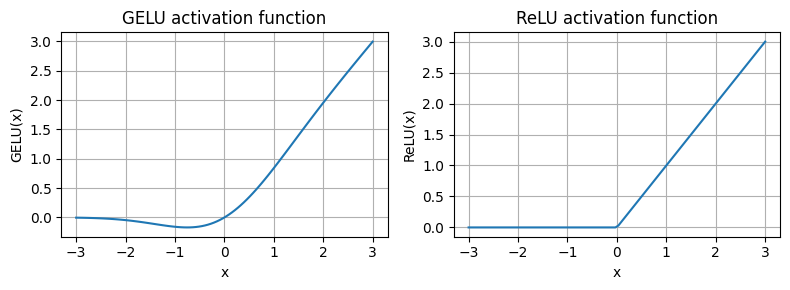

In [31]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

### 4.2.2 Shortcut Connection 

In [32]:
class DummyDeepNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut = False):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            out = layer(x)
            if self.use_shortcut and x.shape == out.shape:
                x = out + x
            else:
                x = out
        return x
    
def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target and output are
    loss = nn.MSELoss()(output, target)
    
    # Backward pass to compute gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [33]:
layer_sizes = [3, 3, 3, 3, 3, 1]  

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = DummyDeepNetwork(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)
print("--" * 30)

# if commented the `torch.manual_seed(123)` line, the gradients will be smaller
torch.manual_seed(123)
model_with_shortcut = DummyDeepNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606
------------------------------------------------------------
layers.0.0.weight has gradient mean of 0.22169792652130127
layers.1.0.weight has gradient mean of 0.20694106817245483
layers.2.0.weight has gradient mean of 0.32896995544433594
layers.3.0.weight has gradient mean of 0.2665732502937317
layers.4.0.weight has gradient mean of 1.3258541822433472


### 4.2.3 MLP and SwiGLU Activation

In [34]:
class FeedForward(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(emb_dim, 4 * emb_dim),
            GELU(),
            nn.Linear(4 * emb_dim, emb_dim)
        )

    def forward(self, x):
        return self.layers(x)

## 4.3 Casual MultiHead Attention


### 4.3.1 Causal Attention Mask
In causal attention, the attention weights above the diagonal are masked, ensuring that for any given input, the LLM is unable to utilize future tokens while calculating the context vectors with the attention weight

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch03_compressed/19.webp" width="600px">

In [35]:
context_length = 6
mask = torch.tril(torch.ones(context_length, context_length))
print(mask)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [36]:
seq_len = 6
attn_scores = torch.randn(seq_len, seq_len)
attn_scores.unsqueeze_(0)
print(attn_scores)

tensor([[[-1.2203,  1.3139,  1.0533,  0.1388, -0.2044, -2.2685],
         [-0.9133, -0.4204, -0.6596, -0.7979,  0.1838,  0.2293],
         [ 0.6177, -0.2876,  0.8218,  0.1512, -0.0444,  1.6236],
         [-2.3229,  1.0878,  1.7228,  0.7738,  0.4046, -1.6461],
         [ 1.0720,  1.5026, -0.8190,  0.2686, -0.1281, -1.2838],
         [-0.2901,  1.2767, -0.9948,  1.2176, -0.2282,  1.3382]]])


In [37]:
mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[[-1.2203,    -inf,    -inf,    -inf,    -inf,    -inf],
         [-0.9133, -0.4204,    -inf,    -inf,    -inf,    -inf],
         [ 0.6177, -0.2876,  0.8218,    -inf,    -inf,    -inf],
         [-2.3229,  1.0878,  1.7228,  0.7738,    -inf,    -inf],
         [ 1.0720,  1.5026, -0.8190,  0.2686, -0.1281,    -inf],
         [-0.2901,  1.2767, -0.9948,  1.2176, -0.2282,  1.3382]]])


In [38]:
attn_weights = torch.softmax(masked, dim=-1)
print(attn_weights)

tensor([[[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.3792, 0.6208, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.3801, 0.1537, 0.4662, 0.0000, 0.0000, 0.0000],
         [0.0090, 0.2739, 0.5169, 0.2001, 0.0000, 0.0000],
         [0.2909, 0.4474, 0.0439, 0.1303, 0.0876, 0.0000],
         [0.0590, 0.2825, 0.0291, 0.2663, 0.0627, 0.3004]]])


### 4.3.2 Masking Additional Attention Weights with Dropout

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch03_compressed/22.webp" width="600px">

In [39]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(p=0.5)
example = torch.ones(6, 6)
print(dropout(example))

tensor([[2., 2., 2., 2., 2., 2.],
        [0., 2., 0., 0., 0., 0.],
        [0., 0., 2., 0., 2., 0.],
        [2., 2., 0., 0., 0., 2.],
        [2., 0., 0., 0., 0., 2.],
        [0., 2., 0., 0., 0., 0.]])


In [40]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 1.2416, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.9323, 0.0000, 0.0000, 0.0000],
         [0.0181, 0.5479, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.5817, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.5650, 0.0000, 0.0000, 0.0000, 0.0000]]])


### 4.3.3 Mutli-Head Attention
<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch03_compressed/24.webp" width="600px">

- We simply stack multiple single-head attention modules to obtain a multi-head attention module:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch03_compressed/25.webp" width="600px">

- The main idea behind multi-head attention is to run the attention mechanism multiple times (in parallel) with different, learned linear projections. This allows the model to jointly attend to information from different representation subspaces at different positions.

In [41]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        batch, seq_len, d_in = x.shape
        # As in `CausalAttention`, for inputs where `num_tokens` exceeds `context_length`, 
        # this will result in errors in the mask creation further below. 
        # In practice, this is not a problem since the LLM (chapters 4-7) ensures that inputs  
        # do not exceed `context_length` before reaching this forwar

        keys = self.W_key(x)  # Shape: (batch, seq_len, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (batch, num_tokens, d_out) -> (batch, num_tokens, num_heads, head_dim)
        keys = keys.view(batch, seq_len, self.num_heads, self.head_dim)
        queries = queries.view(batch, seq_len, self.num_heads, self.head_dim)
        values = values.view(batch, seq_len, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention with a casual mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:seq_len, :seq_len]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / self.d_out**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (batch, seq_len, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(batch, seq_len, -1)
        context_vec = self.out_proj(context_vec)  # Optional projection layer

        return context_vec

In [42]:
torch.manual_seed(123)

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

batch_samples = torch.stack((inputs, inputs), dim=0)
batch, context_length, d_in = batch_samples.shape

mha = MultiHeadAttention(
    d_in=3, d_out=2, 
    context_length=context_length, dropout=0.0, num_heads=2
)
context_vec = mha(batch_samples)

print(context_vec)
print(f"Shape of context vector: {context_vec.shape}")

tensor([[[0.3190, 0.4858],
         [0.2941, 0.3906],
         [0.2854, 0.3600],
         [0.2692, 0.3879],
         [0.2636, 0.3935],
         [0.2574, 0.4033]],

        [[0.3190, 0.4858],
         [0.2941, 0.3906],
         [0.2854, 0.3600],
         [0.2692, 0.3879],
         [0.2636, 0.3935],
         [0.2574, 0.4033]]], grad_fn=<ViewBackward0>)
Shape of context vector: torch.Size([2, 6, 2])


## 4.4 Tranformer Block

In [43]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attn = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], 
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ffn = FeedForward(cfg["emb_dim"])
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x 
        x = self.norm1(x)
        x = self.attn(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ffn(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x 


In [44]:
torch.manual_seed(123)
x = torch.randn(2, 6, 768)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 6, 768])
Output shape: torch.Size([2, 6, 768])


## 5. GPT2 Model

In [45]:
class GPT2Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg['n_layers'])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

- Using the configuration of the 124M parameter model, we can now instantiate this GPT model with random initial weights as follows
- We check the 124M parameter model

In [ ]:
torch.manual_seed(123)
model = GPT2Model(GPT_CONFIG_124M)
print(real_batch)

out = model(real_batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
Input batch:
 2

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.1381,  0.0077, -0.1963,  ..., -0.0222, -0.1060,  0.1717],
         [ 0.3698, -0.8434, -0.6849,  ..., -0.5365,  0.2111, -0.3718],
         [ 0.7010, -0.1601, -0.2300,  ...,  0.1428, -0.6814,  0.0556],
         [-0.3878,  0.1701, -0.1727,  ...,  1.1419,  0.5161, -0.5191]],

        [[ 0.1094, -0.2894, -0.1467,  ..., -0.0557,  0.2911, -0.2824],
         [ 0.0966, -0.3174, -0.3489,  ...,  1.2188,  0.0297,  0.1979],
         [ 0.7062,  0.5117, -0.4187,  ...,  0.7558,  0.3132, -0.2127],
         [-0.0743, -0.0966,  0.4021,  ...,  1.2989, -0.4197,  0.0514]]],
       grad_fn=<UnsafeViewBackward0>)


In [49]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


- As we see above, this model has 163M, not 124M parameters; why?
- In the original GPT-2 paper, the researchers applied weight tying, which means that they reused the token embedding layer (`tok_emb`) as the output layer, which means setting `self.out_head.weight = self.tok_emb.weight`
- The token embedding layer projects the 50,257-dimensional one-hot encoded input tokens to a 768-dimensional embedding representation
- The output layer projects 768-dimensional embeddings back into a 50,257-dimensional representation so that we can convert these back into words (more about that in the next section)
- So, the embedding and output layer have the same number of weight parameters, as we can see based on the shape of their weight matrices
- However, a quick note about its size: we previously referred to it as a 124M parameter model; we can double check this number as follows:

In [52]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

total_params_gpt2_bytes = total_params_gpt2 * 4
total_size_mb = total_params_gpt2_bytes / (1024 * 1024)
print(f"Total size of the model in MB: {total_size_mb:.2f} MB")

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])
Number of trainable parameters considering weight tying: 124,412,160
Total size of the model in MB: 474.59 MB


## 6. Generating Text (Decode)
- LLMs like the GPT model we implemented above are used to generate one word at a time

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/16.webp" width="400px">

- The following `generate_text_simple` function implements greedy decoding, which is a simple and fast method to generate text

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/17.webp" width="600px">

In [53]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

In [54]:
start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [56]:
model.eval() # disable dropout

out = generate_text_simple(
    model=model,
    idx=encoded_tensor, 
    max_new_tokens=6, 
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output:", out)
print("Output length:", len(out[0]))

decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 29739,   554]])
Output length: 10
Hello, I am Featureiman Byeswick Exit In
